# IN4640 Assignment 1 Transformations and Neighborhood  Filtering

1. Implement the intensity transformation depicted in Fig. 1a on the image shown in Fig. 1b, read as a
grayscale image.

(a) Implement the transformation as a 256-entry lookup table (e.g., using cv.LUT or NumPy indexing),
     and show the original and transformed images side by side.


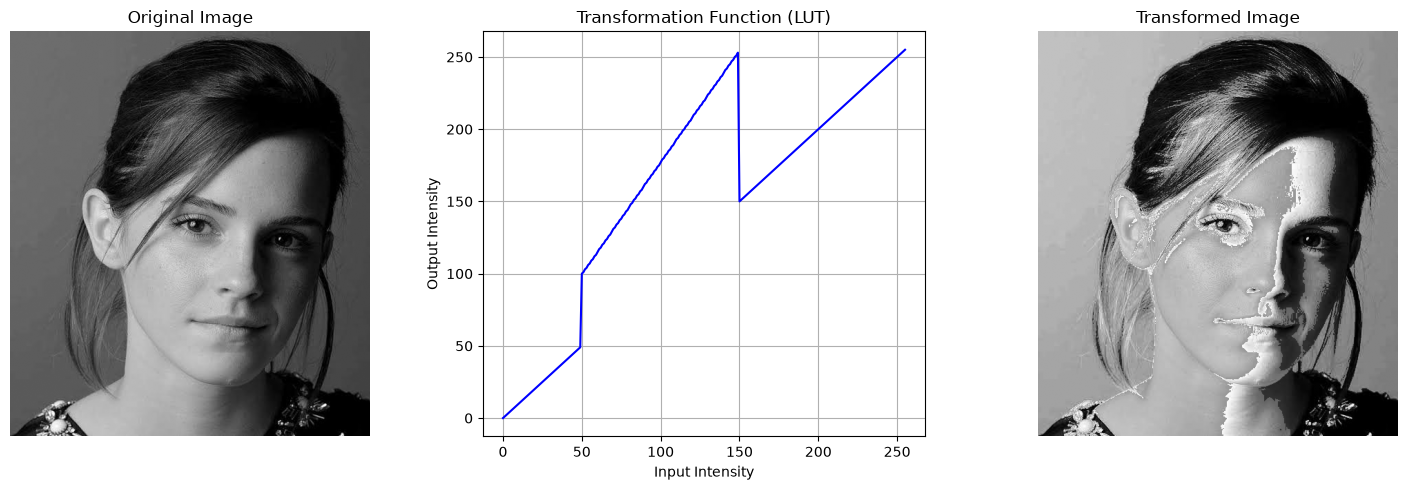

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

img = cv.imread('Images/emma.jpg', cv.IMREAD_GRAYSCALE)


t = np.zeros(256)
t[0:50] = np.arange(0, 50)
t[150:256] = np.arange(150, 256)
t[50:150] = 1.55 * np.arange(50, 150) + 22.5
t = np.clip(t, 0, 255).astype(np.uint8)


img_transformed = cv.LUT(img, t)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].plot(t, color='blue')
axes[1].set_title('Transformation Function (LUT)')
axes[1].set_xlabel('Input Intensity')
axes[1].set_ylabel('Output Intensity')
axes[1].grid(True)

axes[2].imshow(img_transformed, cmap='gray')
axes[2].set_title('Transformed Image')
axes[2].axis('off')

plt.tight_layout()
plt.show()

(b) Explain the visual effect of the transformation. In particular, what happens to pixels with intensities just below and just above 50 and 150?
<br>
<span style="color: blue;"> 
Increases the brightness and contrast of pixels with intensities between 50 and 150.
Pixels below 50 and at or above 150 remain unchanged.
 </span>

## Question 2 – Intensity Transformation for Brain Tissue Enhancement

Apply an intensity transformation similar to Question 1 to accentuate the following tissues in the brain Proton Density (PD) image shown in **Figure 2**:

**(a)** White matter

**(b)** Gray matter

1. Apply a suitable intensity transformation to enhance white matter.
2. Apply a suitable intensity transformation to enhance gray matter.
3. Plot the intensity transformation functions for both cases.
4. Display the resulting enhanced images.
5. State the intensity ranges selected for each tissue and explain how you chose those ranges.



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..246.5].


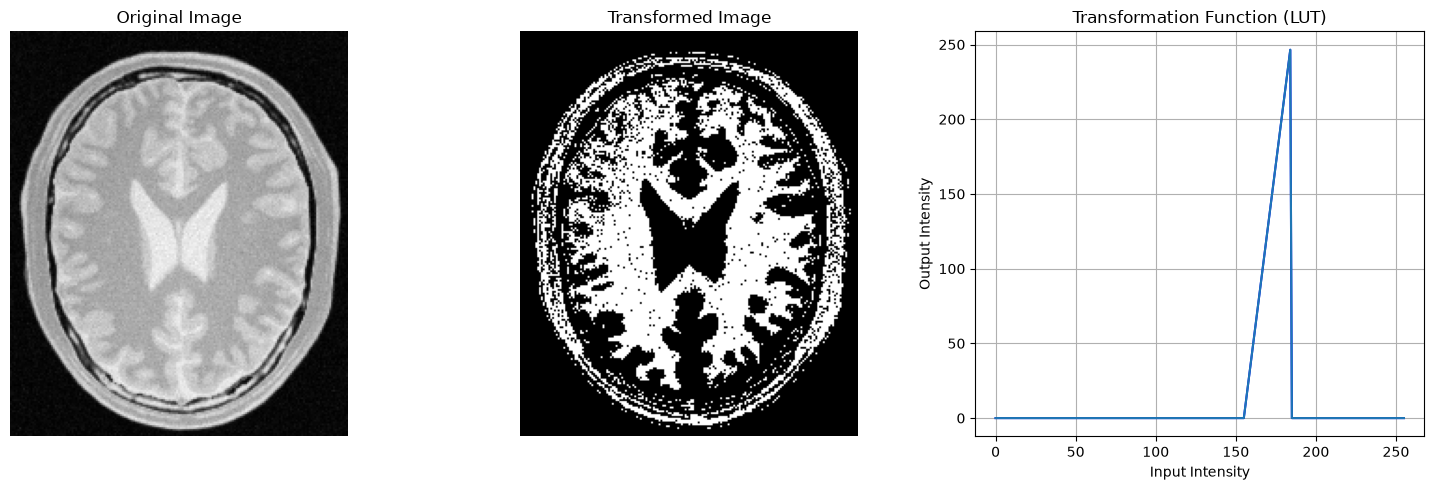

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

im = cv.imread("Images/brain.png")

t = np.zeros(256)
t[155:185] = 255/30 * np.arange(155, 185) - 255/30*155

g = t[im]

# plot the original image and the transformed image and transformtion function
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(im, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(g, cmap='gray')
axes[1].set_title('Transformed Image')
axes[1].axis('off')

axes[2].plot(t, color='blue')
axes[2].set_title('Transformation Function (LUT)')
axes[2].set_xlabel('Input Intensity')
axes[2].set_ylabel('Output Intensity')
axes[2].grid(True)

plt.tight_layout()
plt.plot(t)
plt.show()


## Question 3 [10 Marks]

Consider the image shown in Fig. 31.

### (a)
Apply gamma correction to the L plane in the L∗a∗b∗ color space and state the γ value. Normalize the L plane to [0,1] before applying the power law, and leave the a∗ and b∗ planes unchanged.

### (b)
Show the histograms of the L plane of the original and corrected images.

### (c)
Why is the correction applied to the L plane rather than to each of the R, G, and B planes?

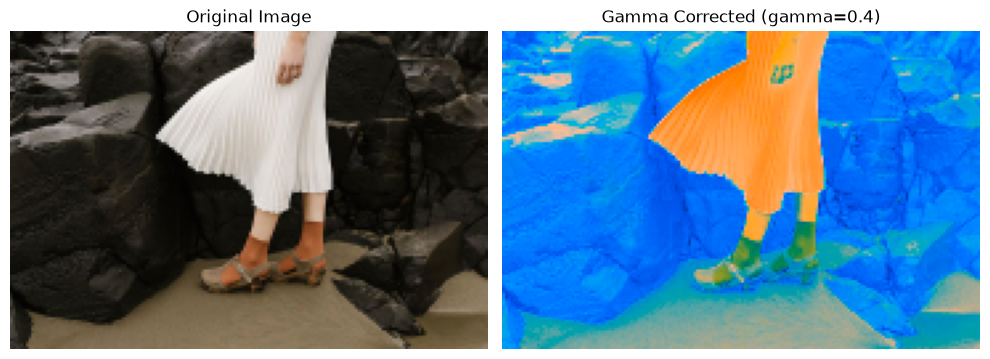

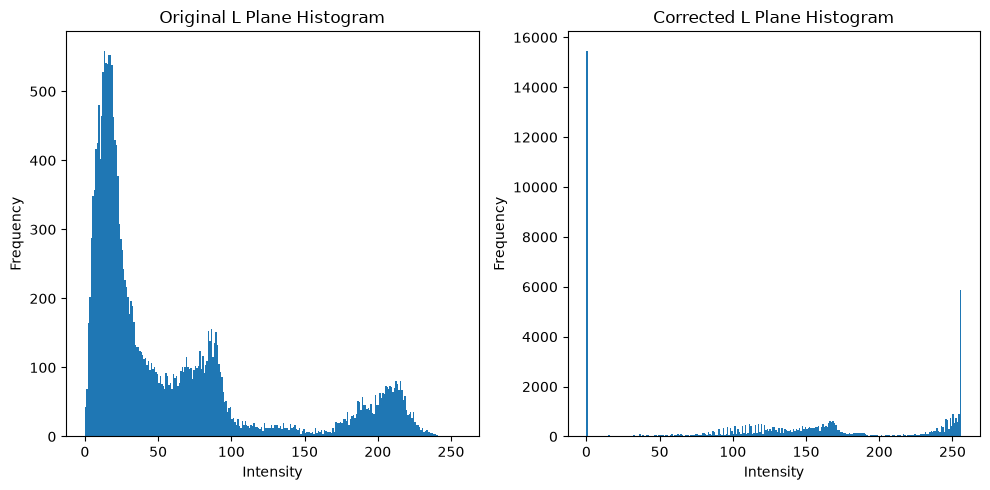

In [22]:
import cv2 as cv
import matplotlib.pyplot as plt

f = cv.imread("Images/highlights_and_shadows.jpg", cv.COLOR_BGR2LAB) # Produce channels Light, Green and Blue

L, a, b = cv.split(f)

# normalize the L plane
L_norm = cv.normalize(L, None, 0, 1, cv.NORM_MINMAX, dtype=cv.CV_32F)

# gamma correction of the L plane
gamma = 0.4
L_powered = np.power(L_norm, gamma)

#Turn pixel values back to 255
L_corrected = np.uint8(L_powered * 255)

# merge L, a , b
f_corrected = cv.merge((L_corrected, a, b))

# cvt color format batck to BGR
corrected_f = cv.cvtColor(f_corrected, cv.COLOR_LAB2BGR)

# Display original and corrected images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(f, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(corrected_f, cv.COLOR_BGR2RGB))
plt.title(f'Gamma Corrected (gamma={gamma})')
plt.axis('off')

plt.tight_layout()
plt.show()

# Display histograms of original and corrected L planes
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.hist(L.ravel(), bins=256, range=(0, 256))
plt.title('Original L Plane Histogram')
plt.xlabel('Intensity')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(corrected_f.ravel(), bins=256, range=(0, 256))
plt.title('Corrected L Plane Histogram')
plt.xlabel('Intensity')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()
 


<ul> <li>The L plane represents lightness. Since we need to make show dark spots of the image using the gamma correction Gamma correction need to apply to Light plane.</li></ul> 

## 4. Vibrance Enhancement Using Saturation Transformation [10 Marks]

Increasing the vibrance of a photograph can be achieved by applying an intensity transformation to the saturation plane, defined as:

\[
f(x)=\min\left(x+a\times128e^{-\frac{(x-128)^2}{2\sigma^2}},\ 255\right)
\]

where:

- \(x \in [0,255]\) is the input intensity.
- \(a \in [0,1]\) is the adjustment parameter.
- \(\sigma = 70\).

### Tasks

**(a)** Split the image shown in Fig. 4 into Hue, Saturation, and Value planes.

**(b)** Apply the aforementioned intensity transformation to the saturation plane.

**(c)** Adjust \(a\) to obtain a visually pleasing output. Report the selected value of \(a\).

**(d)** Recombine the three planes to obtain the vibrance-enhanced image.

**(e)** Display the following:

- Original image.
- Vibrance-enhanced image.
- Intensity transformation curve.

**(f)** Explain how this transformation differs from multiplying the saturation values by a constant factor. Consider pixels with low, medium, and high saturation values in your explanation.

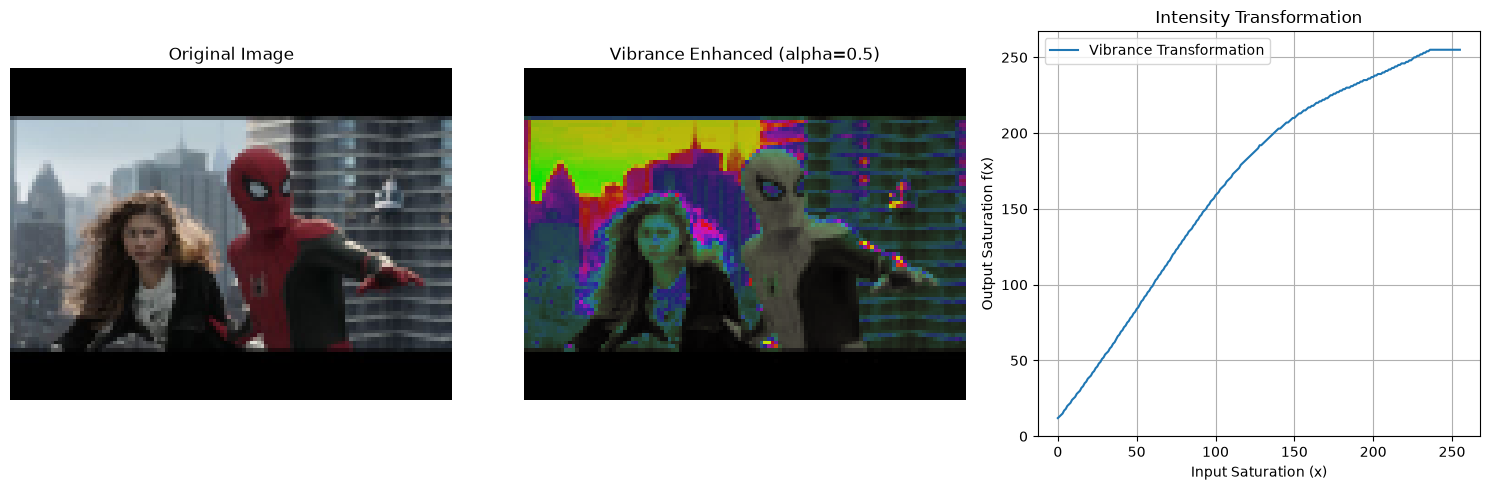

Selected a value: 0.5


In [10]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Convert imge to HSV color format
img = cv.imread('Images/spider-man.jpg', cv.COLOR_BGR2HSV)

# Split img to H, S, V
h, s, v =  cv.split(img)

sigma = 70
alpha = 0.5



# Transformation function
x = np.arange(256)
f = np.minimum(
    x + alpha * 128 * np.exp(-((x - 128) ** 2) / (2 * sigma ** 2)),
    255
).astype(np.uint8)

# Apply transformation function
s_applied = cv.LUT(s, f.astype(np.uint8))

# recombine HSV planes
img_combined = cv.merge([h, s_applied, v])

# Convert back to BGR
final_img = cv.cvtColor(img_combined, cv.COLOR_HSV2BGR)


plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Vibrance enhanced image
plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(final_img, cv.COLOR_BGR2RGB))
plt.title(f"Vibrance Enhanced (alpha={alpha})")
plt.axis("off")

# Transformation curve
plt.subplot(1, 3, 3)
plt.plot(x, f, label="Vibrance Transformation")
plt.xlabel("Input Saturation (x)")
plt.ylabel("Output Saturation f(x)")
plt.title("Intensity Transformation")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


print("Selected a value:", alpha)



# Question: Global and Adaptive Histogram Equalization

In this question, we compare **global histogram equalization** and **adaptive histogram equalization** on the low-contrast image shown in Fig. 5 (`shells.tif`).

**[10 Marks]**

### (a) Implement Global Histogram Equalization

Write your own function to perform histogram equalization using the formulas provided in the lecture slides.

- Implement the histogram equalization algorithm from scratch.
- You may use `cv.equalizeHist()` only to compare your implementation with OpenCV's result.

### (b) Apply CLAHE

Apply **Contrast-Limited Adaptive Histogram Equalization (CLAHE)** using `cv.createCLAHE()` with the following configurations:

- Tile grid size: `8 × 8`
- Clip limit: `2`
- Clip limit: `4`

### (c) Visualize the Results

Display the following images along with their corresponding histograms:

1. Original image (`shells.tif`).
2. Globally equalized image (your implementation).
3. CLAHE image with clip limit = 2.
4. CLAHE image with clip limit = 4.

### (d) Compare and Explain the Results

Compare the four results, paying particular attention to:

- **Background:** Observe how the background appearance and contrast change.
- **Fine details:** Examine how much fine detail and texture on the shells become visible.
- **Global vs. Adaptive:** Explain the differences between global histogram equalization and CLAHE.
- **Clip Limit:** Explain what the clip limit controls and how changing it from 2 to 4 affects contrast enhancement.

Image Shape =  (569, 570)
Image datatype =  uint8


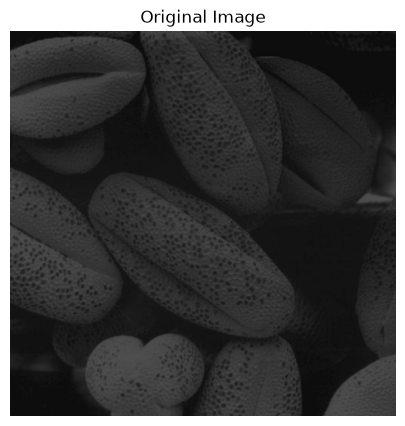

In [7]:
import cv2 as cv
import matplotlib.pyplot as plt



img = cv.imread('Images/shells.jpeg', cv.IMREAD_GRAYSCALE)

print("Image Shape = ", img.shape)
print("Image datatype = ", img.dtype)

plt.figure(figsize=(15, 5))
plt.subplot()
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()


In [61]:
# Implement the Histogram Equalization formula
import numpy as np

def histogram_equalization(img: np.ndarray, L: int = 256) -> np.ndarray:
    hist = np.bincount(img.ravel(), minlength=L)
    N = img.size
    cdf = np.cumsum(hist)
    lookup_table = np.round(((L - 1) / N) * cdf).astype(np.uint8)
    equalized_img = lookup_table[img]
    return equalized_img

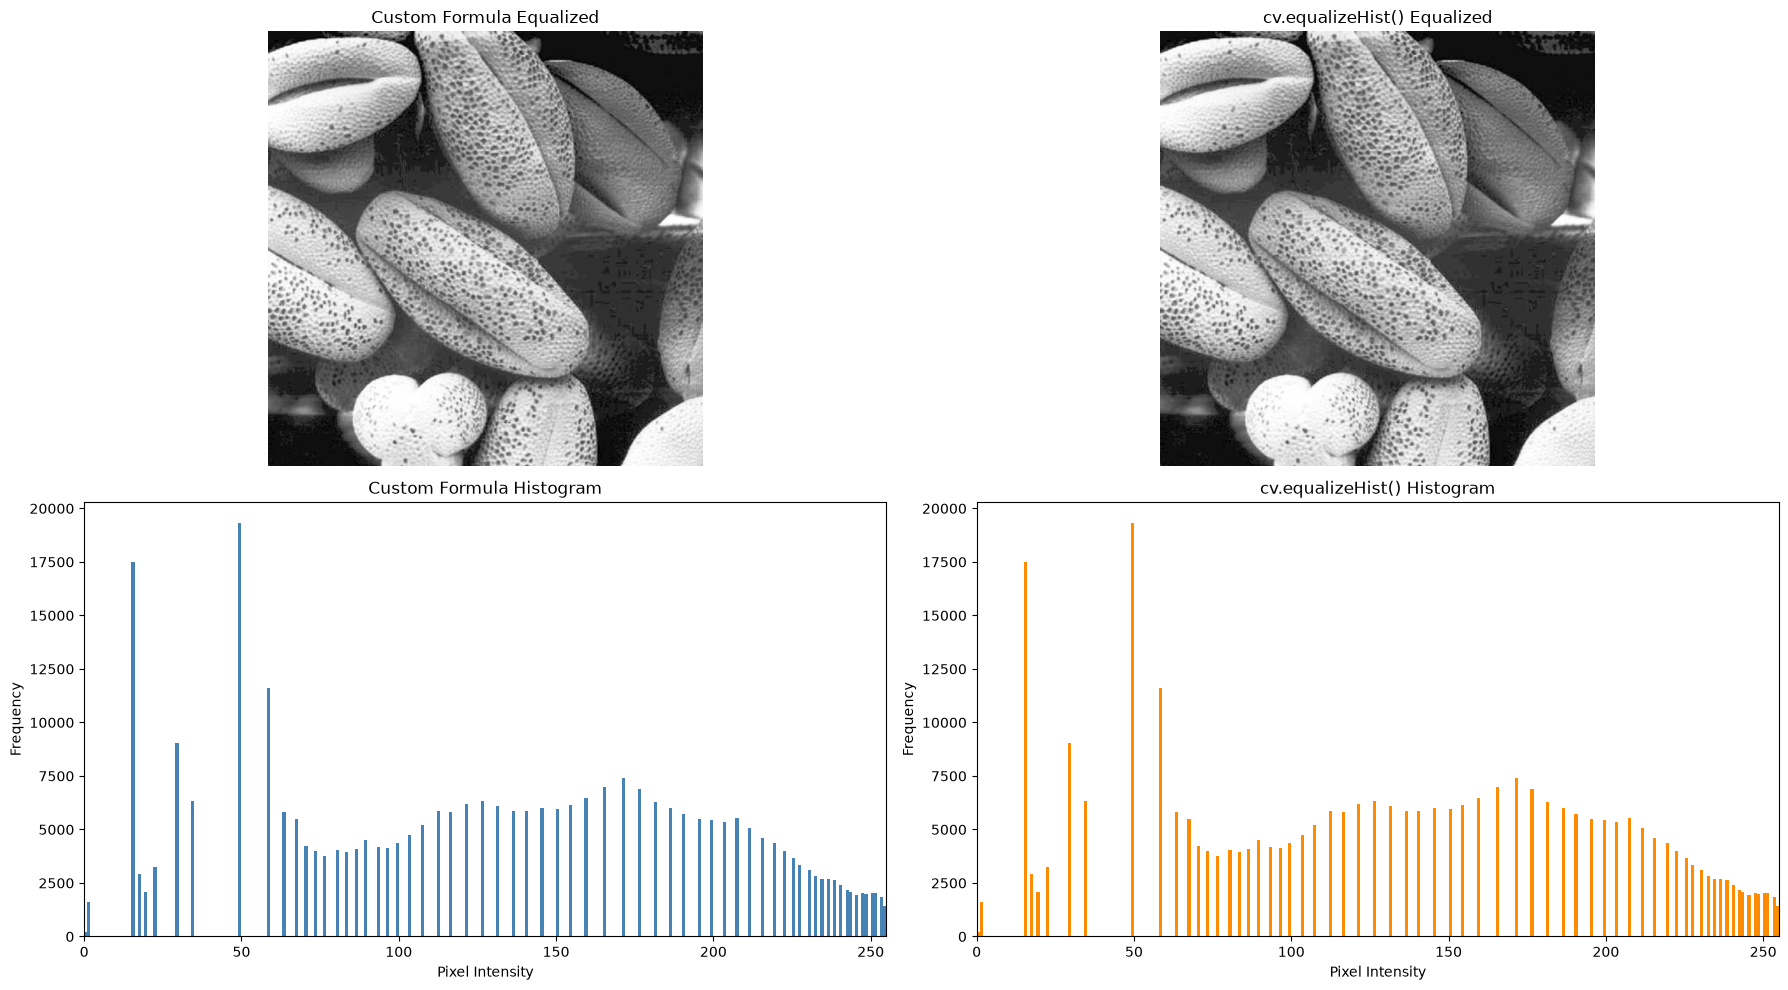

In [12]:
# comparison between developped formula and the cv.equalizeHist()
custom_eq = histogram_equalization(img)
cv_eq = cv.equalizeHist(img)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# Top Row: Images
axes[0, 0].imshow(custom_eq, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Custom Formula Equalized")
axes[0, 0].axis("off")

axes[0, 1].imshow(cv_eq, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("cv.equalizeHist() Equalized")
axes[0, 1].axis("off")


# Bottom Row: Histograms
axes[1, 0].hist(custom_eq.ravel(), bins=256, range=(0, 256), color="steelblue")
axes[1, 0].set_title("Custom Formula Histogram")
axes[1, 0].set_xlabel("Pixel Intensity")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_xlim(0, 255)

axes[1, 1].hist(cv_eq.ravel(), bins=256, range=(0, 256), color="darkorange")
axes[1, 1].set_title("cv.equalizeHist() Histogram")
axes[1, 1].set_xlabel("Pixel Intensity")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_xlim(0, 255)


plt.tight_layout()
plt.show()


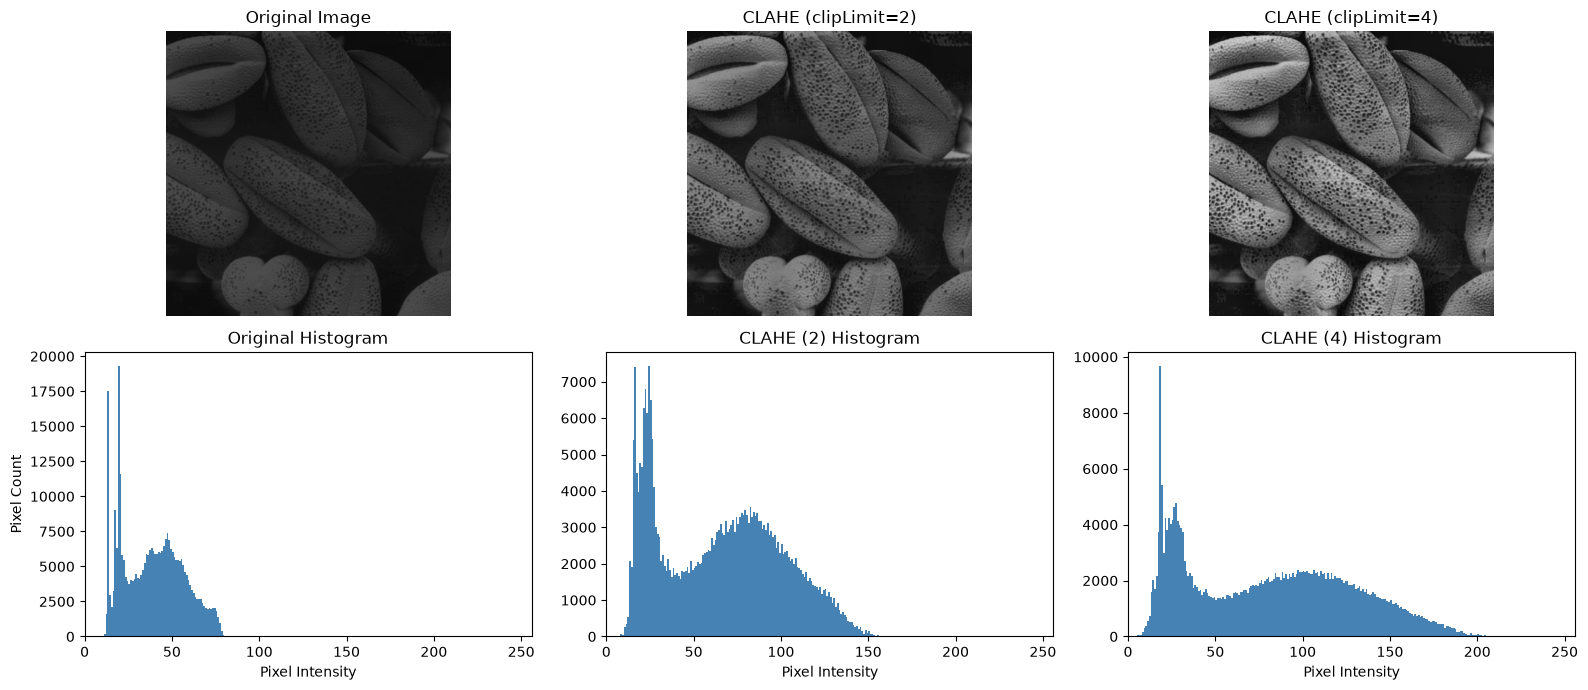

In [16]:
# Apply CLAHE

clahe_2 = cv.createCLAHE(clipLimit=2, tileGridSize=(8,8))
clahe_4 = cv.createCLAHE(clipLimit=4, tileGridSize=(8,8))

applied_clahe_2 = clahe_2.apply(img)
applied_clahe_4 = clahe_4.apply(img)


#  Show the original image, the globally equalized image, and the two CLAHE images, together with their histograms

fig, axes = plt.subplots(2, 3, figsize=(16, 7))

axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[1, 0].hist(img.ravel(), bins=256, range=(0, 256), color='steelblue')
axes[1, 0].set_title('Original Histogram')
axes[1, 0].set_xlabel('Pixel Intensity')
axes[1, 0].set_ylabel('Pixel Count')
axes[1, 0].set_xlim(0, 256)

axes[0, 1].imshow(applied_clahe_2, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title('CLAHE (clipLimit=2)')
axes[0, 1].axis('off')

axes[1, 1].hist(applied_clahe_2.ravel(), bins=256, range=(0, 256), color='steelblue')
axes[1, 1].set_title('CLAHE (2) Histogram')
axes[1, 1].set_xlabel('Pixel Intensity')
axes[1, 1].set_xlim(0, 256)

axes[0, 2].imshow(applied_clahe_4, cmap='gray', vmin=0, vmax=255)
axes[0, 2].set_title('CLAHE (clipLimit=4)')
axes[0, 2].axis('off')

axes[1, 2].hist(applied_clahe_4.ravel(), bins=256, range=(0, 256), color='steelblue')
axes[1, 2].set_title('CLAHE (4) Histogram')
axes[1, 2].set_xlabel('Pixel Intensity')
axes[1, 2].set_xlim(0, 256)

plt.tight_layout()
plt.show()

# Question 6 – Histogram Equalization of the Foreground

In this question, we apply histogram equalization **only to the foreground** of an image to produce an image with a histogram-equalized foreground.

**[10 Marks]**


### (a) Split the Image into HSV Planes
- Open the image shown in Fig. 6.
- Convert the image from BGR to HSV color space.
- Split the image into Hue (H), Saturation (S), and Value (V) planes.
- Display the three planes in grayscale.

### (b) Extract the Foreground Mask
- Identify the appropriate HSV plane for foreground extraction.
- Apply thresholding to this plane to extract the foreground.
- Generate a binary foreground mask.

### (c) Extract the Foreground Value Plane
- Use `cv.bitwise_and()` to extract the foreground from the Value (V) plane using the binary mask.
- Compute the histogram using **only the pixels inside the foreground mask**.
- Ensure that background zeros are excluded from the histogram calculation, as they would otherwise dominate the histogram.

### (d) Compute the Cumulative Histogram
- Calculate the cumulative sum of the foreground histogram using `np.cumsum()`.

### (e) Apply Histogram Equalization to the Foreground
- Use the histogram equalization formulas provided in the lecture slides.
- Adapt the histogram equalization function implemented in Question 5.
- Modify the function to perform histogram equalization using only the pixels inside the foreground mask.
- Do not use `cv.equalizeHist()`.

### (f) Reconstruct the Final Image
- Extract the background from the original Value (V) plane.
- Combine the original background with the histogram-equalized foreground.
- Merge the modified Value plane with the original Hue (H) and Saturation (S) planes.
- Convert the resulting HSV image back to BGR color space.

### Required Visualizations
Display the following:

1. Original image.
2. Hue (H) plane in grayscale.
3. Saturation (S) plane in grayscale.
4. Value (V) plane in grayscale.
5. Binary foreground mask.
6. Final image with histogram equalization applied only to the foreground.


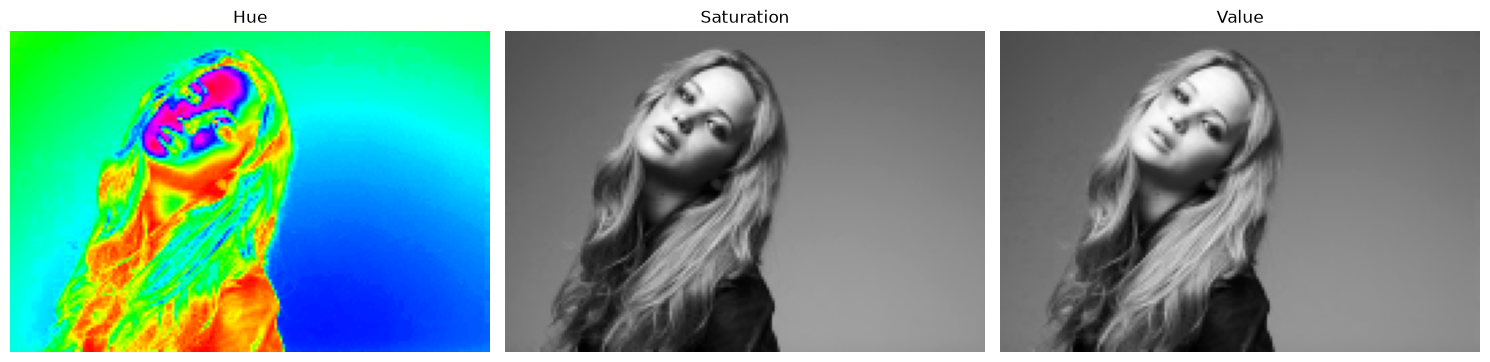

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt

# read original image
im = cv.imread("Images/jeniffer.jpg", cv.COLOR_BGR2HSV)

# Split image to Hue, Stureation and Value
h, s, v = cv.split(im)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(h, cmap="hsv")
axes[0].set_title("Hue")
axes[0].axis("off")

axes[1].imshow(s, cmap="gray")
axes[1].set_title("Saturation")
axes[1].axis("off")

axes[2].imshow(v, cmap="gray")
axes[2].set_title("Value")
axes[2].axis("off")

plt.tight_layout()
plt.show()

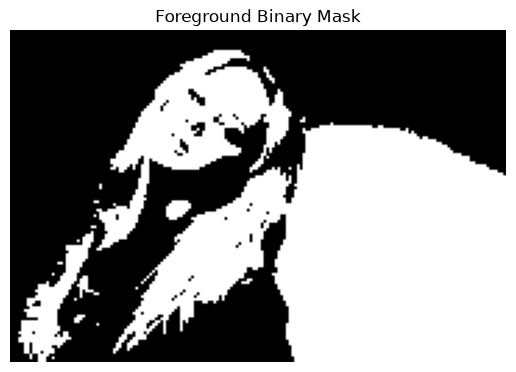

In [39]:
#  Value plane to threshold to extract the foreground mask. A mask is a binary image.
import matplotlib.pyplot as plt
import cv2 as cv

_, mask = cv.threshold(v, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)


# Display the binary mask
plt.imshow(mask, cmap="gray")
plt.title("Foreground Binary Mask")
plt.axis("off")
plt.show()


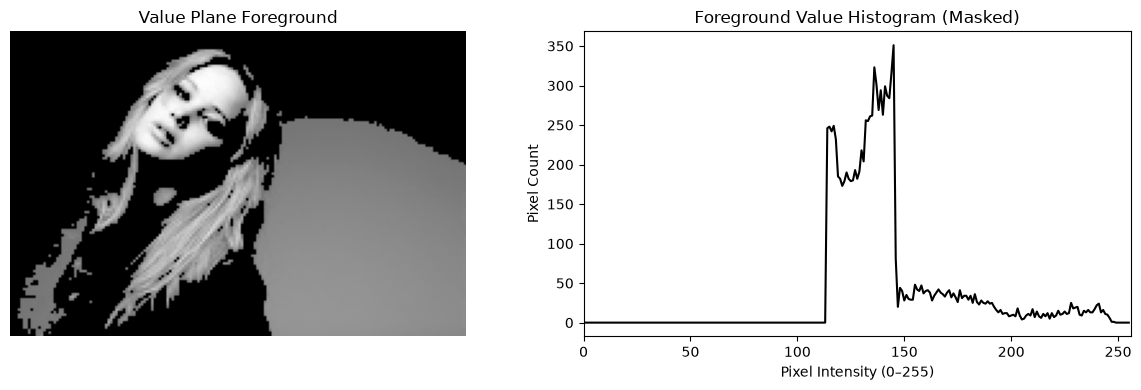

In [ ]:
import matplotlib.pyplot as plt
import cv2 as cv

#  obtain the foreground of the value plane using cv.bitwise_and
foreground = cv.bitwise_and(v, mask)

# compute the histogram
hist = cv.calcHist([v], [0], mask, [256], [0, 256])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(foreground, cmap="gray")
axes[0].set_title("Value Plane Foreground")
axes[0].axis("off")

axes[1].plot(hist, color="black")
axes[1].set_title("Foreground Value Histogram (Masked)")
axes[1].set_xlabel("Pixel Intensity (0–255)")
axes[1].set_ylabel("Pixel Count")
axes[1].set_xlim([0, 256])

plt.tight_layout()
plt.show()

[   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.  246.  494.  736.  985. 1217. 1402.
 1584. 1757. 1936. 2126. 2308. 2487. 2667. 2860. 3042. 3233. 3451. 3655.
 3911. 4166. 4427. 4689. 5012. 5313. 5582. 5876. 6139. 6438. 6725. 7009.
 7325. 7676. 7757. 7777. 7821. 7861. 7889. 7924. 7954. 7983. 8012. 8060.
 8102. 8142. 8189. 8226. 8266. 8307. 8345. 8373. 84

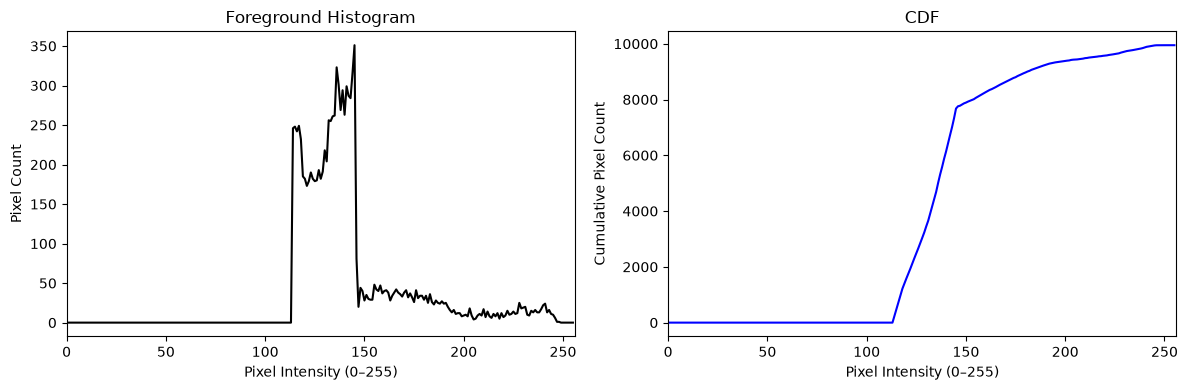

In [ ]:
#  the cumulative sum of the histogram using np.cumsum
import numpy as np

# Calculate CDF
cdf = np.cumsum(hist)
print(cdf)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist, color="black")
axes[0].set_title("Foreground Histogram")
axes[0].set_xlabel("Pixel Intensity (0–255)")
axes[0].set_ylabel("Pixel Count")
axes[0].set_xlim([0, 256])

axes[1].plot(cdf, color="blue")
axes[1].set_title("CDF")
axes[1].set_xlabel("Pixel Intensity (0–255)")
axes[1].set_ylabel("Cumulative Pixel Count")
axes[1].set_xlim([0, 256])

plt.tight_layout()
plt.show()

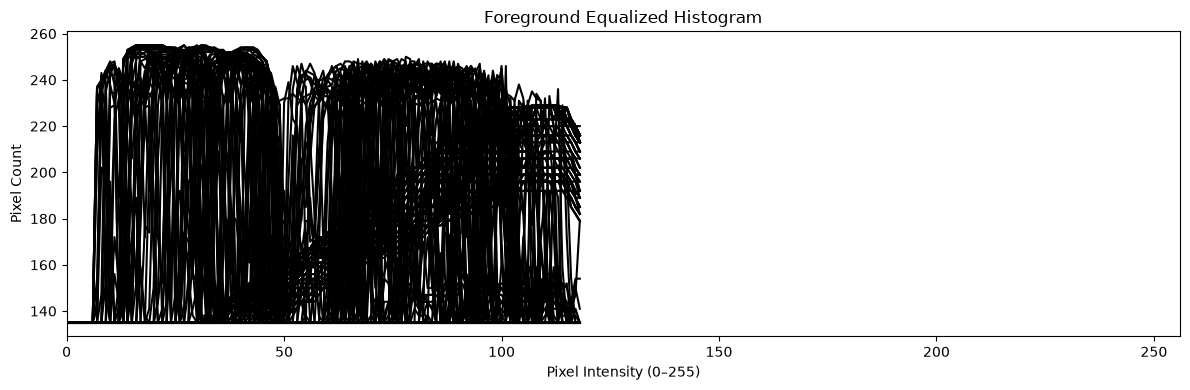

In [64]:
# Equalize the histogram using formula in question 5

equaized = histogram_equalization(foreground)


fig, axes = plt.subplots(1, 1, figsize=(12, 4))

axes.plot(equaized, color="black")
axes.set_title("Foreground Equalized Histogram")
axes.set_xlabel("Pixel Intensity (0–255)")
axes.set_ylabel("Pixel Count")
axes.set_xlim([0, 256])
plt.tight_layout()
plt.show()



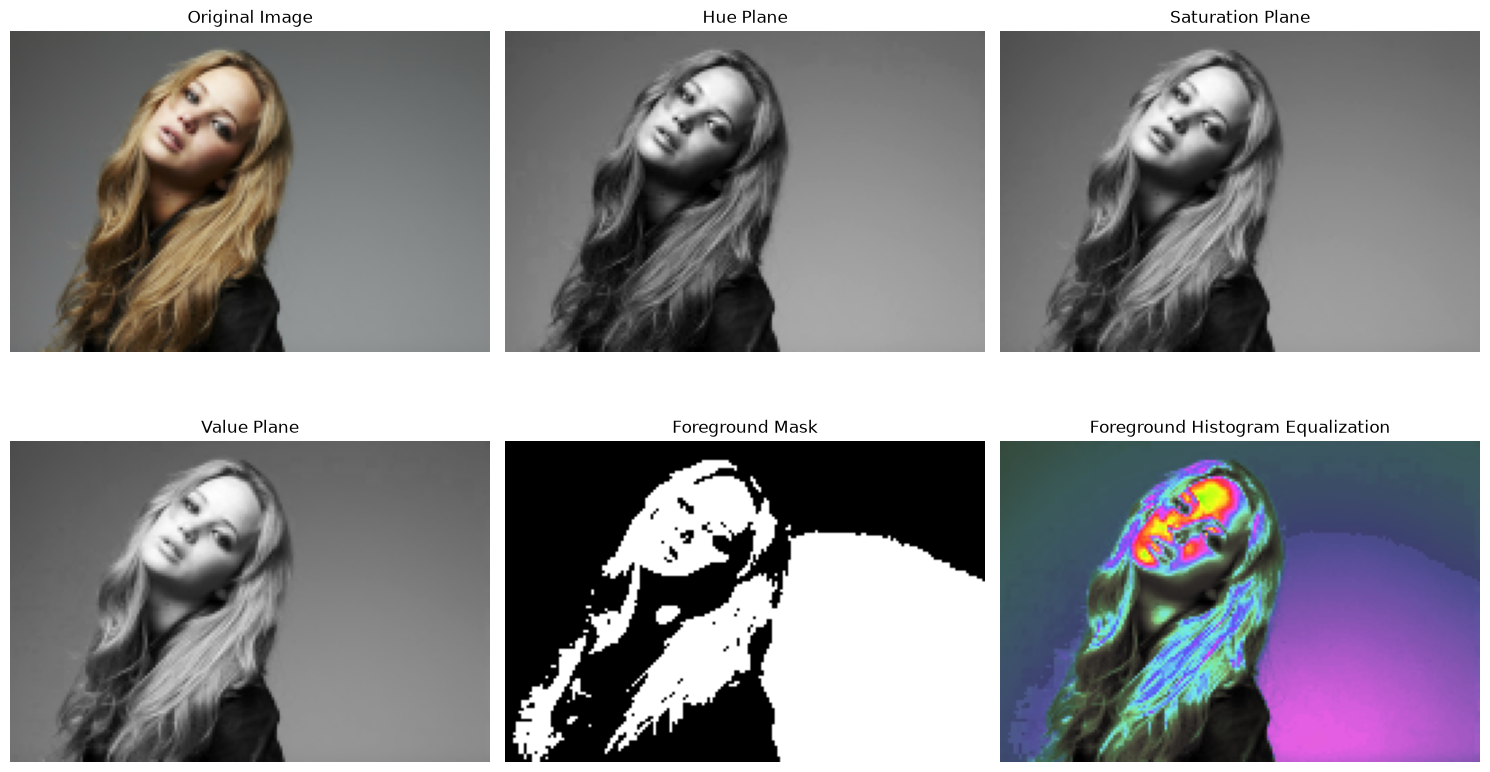

In [ ]:
# Extract background 
background =  cv.bitwise_and(v,v, mask=cv.bitwise_not(mask))

# combine foreground and background
final_v = cv.add(
    cv.bitwise_and(equaized, equaized, mask=mask),
    background
)

hsv_combined = cv.merge([h, s, final_v])

result = cv.cvtColor(hsv_combined, cv.COLOR_HSV2BGR)


fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Original image (BGR -> RGB)
axes[0, 0].imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
axes[0, 0].set_title("Original Image")

# Hue plane
axes[0, 1].imshow(h, cmap='gray')
axes[0, 1].set_title("Hue Plane")

# Saturation plane
axes[0, 2].imshow(s, cmap='gray')
axes[0, 2].set_title("Saturation Plane")

# Value plane
axes[1, 0].imshow(v, cmap='gray')
axes[1, 0].set_title("Value Plane")

# Foreground mask
axes[1, 1].imshow(mask, cmap='gray')
axes[1, 1].set_title("Foreground Mask")

# Final equalized image 
axes[1, 2].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
axes[1, 2].set_title("Foreground Histogram Equalization")

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

# Question 7 – Linear, Nonlinear, and Edge-Preserving Filters

In this question, we compare linear, nonlinear, and edge-preserving filters for noise removal.

Read the image shown in **Fig. 7 (`einstein.png`)** as a grayscale image \(f\).

Generate all random numbers using:

```python
rng = np.random.default_rng(seed)
```

where `seed` is the numerical part of your index number.

**[15 Marks]**

---

### (a) Noise Generation

Create two noisy images:

1. **Gaussian noise (`g1`):** Add zero-mean Gaussian noise with \(\sigma = 20\) to \(f\) and clip the resulting image to \([0,255]\).

2. **Salt-and-pepper noise (`g2`):** Corrupt 10% of the pixels of \(f\):
   - 5% of the pixels should be set to 0.
   - 5% of the pixels should be set to 255.

### (b) Linear and Nonlinear Filtering

Filter both `g1` and `g2` using the following filters:

1. A \(5 \times 5\) box filter.
2. A Gaussian filter with \(\sigma = 1\).
3. A \(3 \times 3\) median filter.
4. A \(5 \times 5\) median filter.

Write your own implementation of the median filter and verify it against `cv.medianBlur`.

### (c) Bilateral Filtering

Write your own implementation of a bilateral filter using the following equation:

\[
h(p) = \frac{1}{W_p}
\sum_{q \in N(p)}
\exp\left(-\frac{\|p-q\|^2}{2\sigma_s^2}\right)
\exp\left(-\frac{(g(p)-g(q))^2}{2\sigma_r^2}\right)
g(q)
\]

where:

- \(g\) is the input image.
- \(N(p)\) is a square window of radius \(\lceil 3\sigma_s \rceil\), centred at pixel \(p\).
- \(W_p\) is the sum of the weights.

Apply your bilateral filter to `g1` using:

\[
\sigma_s = 2,\qquad \sigma_r = 40
\]

Compare your result with:

1. The output of `cv.bilateralFilter` using matching parameters.
2. The output of a Gaussian filter with \(\sigma = 2\).

Use **zoomed-in crops around edges** to compare the results.

### (d) Effect of the Range Parameter

Show the output of your bilateral filter for the following values:

\[
\sigma_r \in \{10,40,1000\}
\]

Answer the following question:

**What does the bilateral filter become as \(\sigma_r \rightarrow \infty\), and why?**

### (e) PSNR Evaluation and Comparison

Calculate and tabulate the Peak Signal-to-Noise Ratio (PSNR) of all noisy and filtered images with respect to the original image \(f\).

Use the following formula:

\[
PSNR = 10\log_{10}\left(\frac{255^2}{MSE}\right)
\]

Answer the following questions:

1. Which filter is best suited to each type of noise?
2. Explain your observations in terms of how each filter treats outliers and edges.

---

**End of Question 7**

(500, 405)


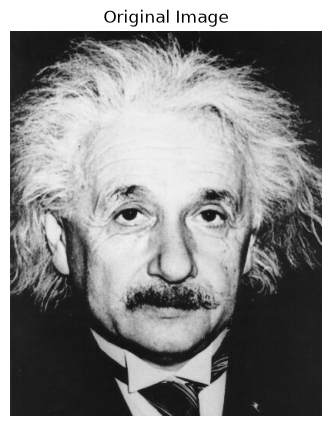

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

f = cv.imread('Images/einstein.jpg', cv.IMREAD_GRAYSCALE)
print(f.shape)

plt.figure(figsize=(15, 5))
plt.subplot()
plt.imshow(cv.cvtColor(f, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

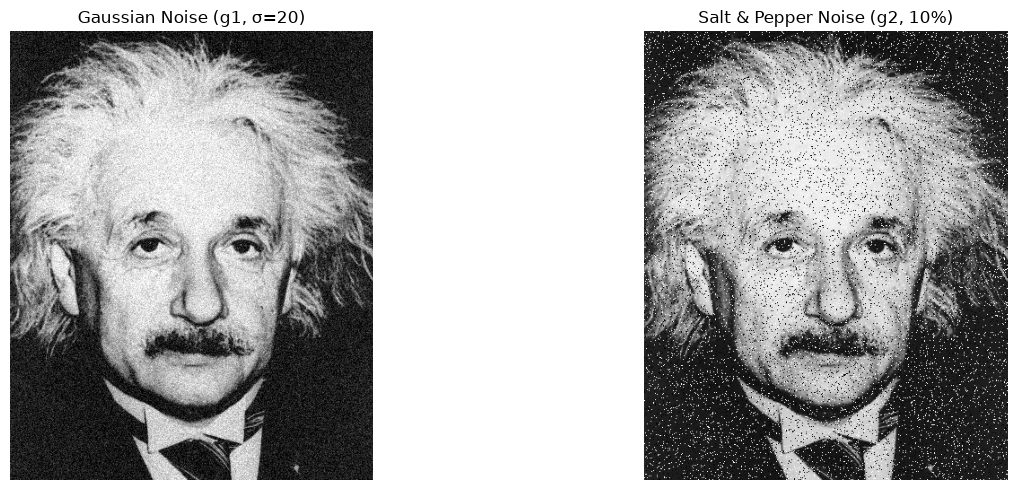

In [2]:
# Generate random number from index number
import numpy as np

seed = 225522
rng = np.random.default_rng(seed)

f_float = f.astype(np.float64)

# Create g1 
gaussian_noise = rng.normal(loc=0.0, scale=20.0, size=f.shape)
g1 = np.clip(f_float + gaussian_noise, 0, 255).astype(np.uint8)

# Create g2
g2 = f.copy()
probs = rng.random(size=f.shape)
g2[probs < 0.05] = 0       
g2[(probs >= 0.05) & (probs < 0.10)] = 255  



fig, (ax2, ax3) = plt.subplots(1, 2, figsize=(15, 5))

# Plot Gaussian Noise (g1)
ax2.imshow(g1, cmap="gray", vmin=0, vmax=255)
ax2.set_title("Gaussian Noise (g1, σ=20)")
ax2.axis("off")

# Plot Salt & Pepper Noise (g2)
ax3.imshow(g2, cmap="gray", vmin=0, vmax=255)
ax3.set_title("Salt & Pepper Noise (g2, 10%)")
ax3.axis("off")

plt.tight_layout()
plt.show()

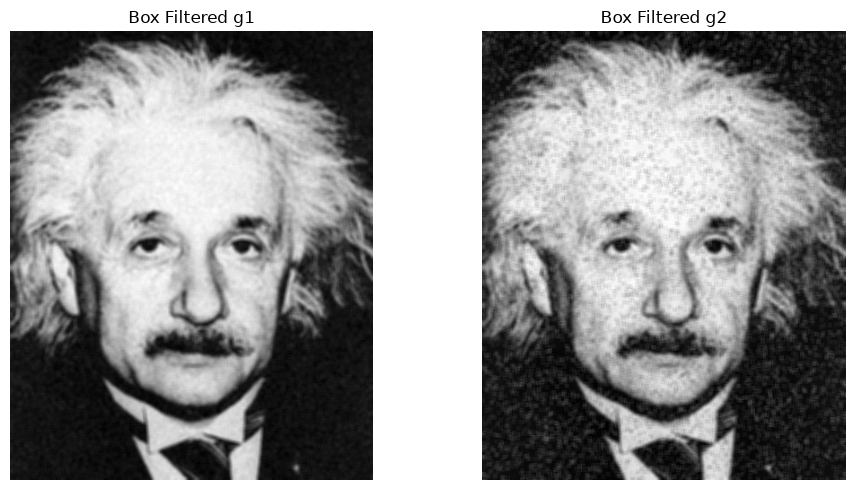

In [3]:
# Box filter apply for g1
ksize = 5
kernal = np.ones((ksize, ksize), np.float32)/ (ksize * ksize)
boxed_g1 = cv.filter2D(g1, -1, kernal)

# Box filter apply for g2
ksize = 5
kernal = np.ones((ksize, ksize), np.float32)/ (ksize * ksize)
boxed_g2 = cv.filter2D(g2, -1, kernal)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(boxed_g1, cmap='gray')
axes[0].set_title('Box Filtered g1')
axes[0].axis('off')

axes[1].imshow(boxed_g2, cmap='gray')
axes[1].set_title('Box Filtered g2')
axes[1].axis('off')

plt.tight_layout()
plt.show()

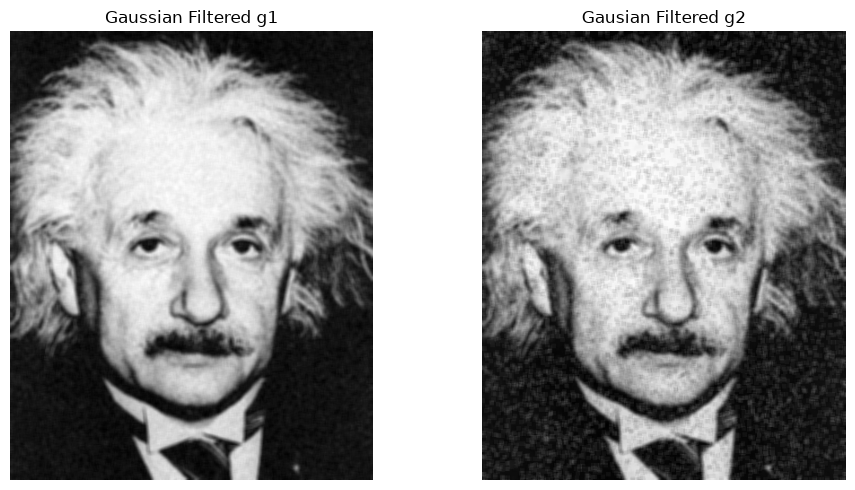

In [4]:
# apply sigma=1 gaussian filter to g1
gaussian_g1 = cv.GaussianBlur(g1,(3,3), 1)

# apply sigma=1 gaussian filter to g2
gaussian_g2 = cv.GaussianBlur(g2,(3,3), 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(boxed_g1, cmap='gray')
axes[0].set_title('Gaussian Filtered g1')
axes[0].axis('off')

axes[1].imshow(boxed_g2, cmap='gray')
axes[1].set_title('Gausian Filtered g2')
axes[1].axis('off')

plt.tight_layout()
plt.show()

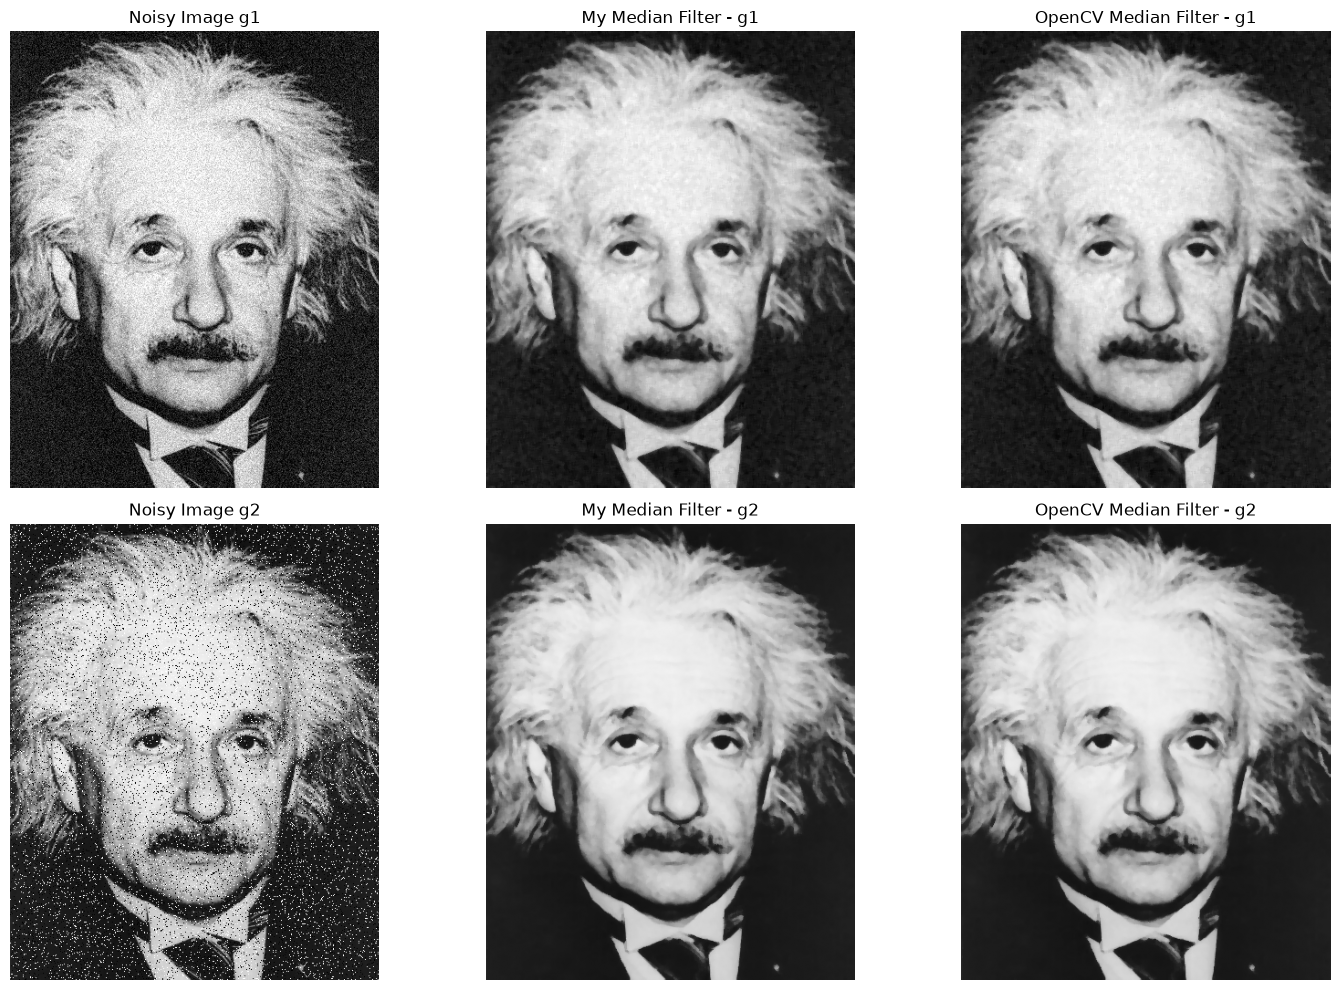

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv



def median_filter(image:np.array):
    height, width = image.shape
    output = np.zeros((height, width), dtype=np.uint8) # Empty output img
    pade = 2
    padded = np.pad(
        image,
        pad_width=pade,
        mode='edge'
    )
    for i in range(height):
        for j in range(width):
            window = padded[i:i+5, j:j+5]
            pixels = window.flatten()
            sorted_pixels = np.sort(pixels)
            median_value = sorted_pixels[12]
            output[i, j] = median_value

    return output
    
    

# Median filter to g1
my_function_median_result_g1 = median_filter(g1)
built_in_function_result_g1 = cv.medianBlur(g1, 5)

# Median filter to g2
my_function_median_result_g2 = median_filter(g2)
built_in_function_result_g2 = cv.medianBlur(g2, 5)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# First row: g1
axes[0, 0].imshow(g1, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Noisy Image g1")

axes[0, 1].imshow(my_function_median_result_g1, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("My Median Filter - g1")

axes[0, 2].imshow(built_in_function_result_g1, cmap='gray', vmin=0, vmax=255)
axes[0, 2].set_title("OpenCV Median Filter - g1")


# Second row: g2
axes[1, 0].imshow(g2, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title("Noisy Image g2")

axes[1, 1].imshow(my_function_median_result_g2, cmap='gray', vmin=0, vmax=255)
axes[1, 1].set_title("My Median Filter - g2")

axes[1, 2].imshow(built_in_function_result_g2, cmap='gray', vmin=0, vmax=255)
axes[1, 2].set_title("OpenCV Median Filter - g2")


# Remove axis ticks
for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# built own bilaterial filter

def bileterial_filter(image:np.array):
    height, width = image.size
    filtered = np.zeros((height, width), dtype=np.uint8)
    padded = np.pad(image, pad_width=)